# ScamLens-AI: Binary Scam Classification & Triage Benchmark

This notebook evaluates scam detection against real-world sample messages (`data/sample_data.json`) using the **ScamLens-AI Prompt Catalog** (`binary_triage_v1.yaml`) and universal AI client (Groq Llama-3.3, OpenAI, Ollama, etc.).

### Problem Formulation:
The dataset provides flat binary ground truth labels (`0 = Legitimate`, `1 = Scam/Spam`).
To avoid mismatched fine-grained categories (like `PHISHING`, `UPI_FRAUD`, `IMPERSONATION`), the model is prompted to predict strictly:
- **`1`**: Scam / Fraud / Phishing / Deceptive Spam
- **`0`**: Legitimate / Benign Personal / Transactional
- **`None` (`null`)**: Ambiguous / Insufficient context to determine


In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import sys
import json
import time
from pathlib import Path
from dotenv import load_dotenv
from random import sample

# Ensure project root and src are on sys.path
project_root = Path("..").resolve() if Path("../src").exists() else Path(".").resolve()
src_path = project_root / "src"
if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

# Load environment variables from .env
env_file = project_root / ".env"
load_dotenv(env_file) if env_file.exists() else load_dotenv()

from scamlens.ai import get_ai_client, load_prompt, list_available_prompts
from scamlens.core.config import get_settings

settings = get_settings()
client = get_ai_client()

print(f"Project root: {project_root}")
print(f"AI Provider:  {settings.default_ai_provider.upper()}")
print(f"Target Model: {client.model}")
print(f"API Key configured: {bool(client.api_key)}")

Project root: /Users/vishnureddy/PycharmProjects/ScamLens-AI
AI Provider:  CUSTOM
Target Model: Qwen/Qwen3-8B
API Key configured: True


In [3]:
# Load sample dataset
candidates = [
    project_root / "data" / "sample_data.json",
    project_root / "data" / "data.json",
]
data_path = next((p for p in candidates if p.is_file()), None)

if not data_path:
    raise FileNotFoundError(f"Dataset not found in candidates: {candidates}")

with open(data_path, "r", encoding="utf-8") as f:
    data_json = json.load(f)

rows = data_json.get("rows", [])
total_rows = len(rows)
legit_count = sum(1 for r in rows if r.get("label") == 0)
scam_count = sum(1 for r in rows if r.get("label") == 1)

print(f"Successfully loaded {total_rows} records from: {data_path.relative_to(project_root)}")
print(f"Class Distribution: {legit_count} Legitimate (0) | {scam_count} Scam/Spam (1)")

Successfully loaded 3787 records from: data/sample_data.json
Class Distribution: 3040 Legitimate (0) | 747 Scam/Spam (1)


In [4]:
# Load dedicated binary/ternary triage prompt (predicts 1, 0, or null)
available = list_available_prompts()
print(f"Available catalog prompts: {available}")

# Prompt & Evaluation Versioning: Switch between 'v1' (baseline) and 'v2' (enhanced rules)
PROMPT_VERSION = "v2"  # Set to 'v1' or 'v2'
prompt_name = f"binary_triage_{PROMPT_VERSION}" if f"binary_triage_{PROMPT_VERSION}" in available else "binary_triage_v1"
prompt = load_prompt(prompt_name)

print(f"\nLoaded prompt template: '{prompt.name}' (v{prompt.version})")
print(f"Description:      {prompt.description}")
print(f"Input variables:  {prompt.input_variables}")
print(f"Model parameters: {prompt.model_parameters}")
print(f"Few-shot pairs:   {len(prompt.few_shot_examples)}")


Available catalog prompts: ['action_guidance_v1', 'binary_triage_v1', 'binary_triage_v2', 'evidence_synthesis_v1', 'investigation_agent_v1', 'text_triage_v1', 'vision_screenshot_v1']

Loaded prompt template: 'binary_triage_v2' (v2.0.0)
Description:      Enhanced ternary/binary scam triage v2 with targeted rules for reverse-billing traps, fake voicemails, phishing lures, and broadcasts.
Input variables:  ['text']
Model parameters: {'temperature': 0.0, 'max_tokens': 120, 'response_format': 'json_object'}
Few-shot pairs:   5


In [5]:
# Helper function to parse 1 / 0 / None from model response
def parse_prediction(content: str):
    """Extract prediction (1, 0, or None), confidence, and reason from JSON or text response."""
    try:
        # Strip markdown fences if present
        raw = content.strip()
        if raw.startswith('```'):
            lines = raw.splitlines()
            if lines[0].startswith('```'):
                lines = lines[1:]
            if lines and lines[-1].startswith('```'):
                lines = lines[:-1]
            raw = '\n'.join(lines).strip()
        if not raw.startswith('{') and '{' in raw:
            raw = raw[raw.find('{'):raw.rfind('}') + 1]
        parsed = json.loads(raw)
        pred = parsed.get("prediction")
        if pred in (0, 1):
            pred_label = pred
        elif pred is None and "is_suspicious" in parsed:
            is_susp = parsed.get("is_suspicious")
            pred_label = 1 if is_susp is True else (0 if is_susp is False else None)
        else:
            pred_label = None
        confidence = parsed.get("confidence")
        reason = parsed.get("reason") or parsed.get("summary", "")
        return pred_label, confidence, reason
    except Exception:
        upper = content.upper()
        if "SCAM" in upper or "SUSPICIOUS" in upper or '"PREDICTION": 1' in upper:
            return 1, None, content[:80]
        elif "LEGITIMATE" in upper or "BENIGN" in upper or "SAFE" in upper or '"PREDICTION": 0' in upper:
            return 0, None, content[:80]
        return None, None, content[:80]

# Single test inference on a sample (with concurrency retry)
sample_idx = 4  # First spam message in dataset
sample_text = rows[sample_idx]["text"]
sample_label = rows[sample_idx].get("label")

messages = prompt.render_messages(text=sample_text)

for attempt in range(3):
    try:
        response = client.chat_completion(
            messages=messages,
            temperature=prompt.model_parameters.get("temperature", 0.0),
            max_tokens=500,
        )
        content = response["choices"][0]["message"].get("content", "")
        pred_label, confidence, reason = parse_prediction(content)
        break
    except Exception as exc:
        if "429" in str(exc) and attempt < 2:
            print(f"  [429 busy] Waiting 2s before retry {attempt+1}...")
            time.sleep(2.0)
        else:
            raise

print(f"Sample [{sample_idx}]: {sample_text}")
print(f"True Label:      {sample_label} (0=Legitimate, 1=Scam)")
print(f"Predicted Label: {pred_label} (0=Legit, 1=Scam, None=Uncertain)")
print(f"Confidence:      {confidence}")
print(f"Model Reason:    {reason}")


Sample [4]: SPJanuary Male Sale! Hot Gay chat now cheaper, call 08709222922. National rate from 1.5p/min cheap to 7.8p/min peak! To stop texts call 08712460324 (10p/min)
True Label:      1 (0=Legitimate, 1=Scam)
Predicted Label: 1 (0=Legit, 1=Scam, None=Uncertain)
Confidence:      0.97
Model Reason:    Unsolicited commercial promotion with premium rate numbers.


In [6]:
# Interactive single-item testing on Positive (Spam) samples
NUM_SAMPLES = 10
DELAY_BETWEEN_CALLS_SEC = 1.0  # Prevents concurrency issues

# Select positive samples only (spam = True / label == 1)
spam_indices = [i for i, r in enumerate(rows) if r.get('label') == 1]
indices = sample(spam_indices, min(NUM_SAMPLES, len(spam_indices)))
results = []

print(f"Evaluating {len(indices)} SPAM samples with model '{client.model}' and prompt '{prompt.name}'...\n")

for count, i in enumerate(indices, start=1):
    row = rows[i]
    query_text = row['text']
    ground_truth = row.get('label')
    
    messages = prompt.render_messages(text=query_text)
    
    try:
        response = client.chat_completion(
            messages=messages,
            temperature=prompt.model_parameters.get('temperature', 0.0),
        )
        content = response['choices'][0]['message'].get('content', '')
        pred_label, confidence, reason = parse_prediction(content)
    except Exception as exc:
        print(f'[{i:4d}] ⚠️ Error: {exc}')
        continue
        
    if pred_label is None:
        status = '❓ UNCERTAIN'
        is_correct = False
    elif pred_label == ground_truth:
        status = '✅ CAUGHT    '
        is_correct = True
    else:
        status = '❌ MISSED    '
        is_correct = False
        
    results.append({
        'index': i,
        'text': query_text,
        'ground_truth': ground_truth,
        'pred_label': pred_label,
        'confidence': confidence,
        'correct': is_correct,
        'reason': reason,
    })
    
    conf_str = f'{confidence:.2f}' if confidence is not None else ' N/A'
    preview = (query_text[:50] + '...') if len(query_text) > 50 else query_text
    print(f'[{i:4d}] {status} | Pred: {str(pred_label):4s} (conf: {conf_str}) | Text: {preview}')
    
    if count < len(indices):
        time.sleep(DELAY_BETWEEN_CALLS_SEC)

# Quick Summary for Positive Testing
caught = sum(1 for r in results if r['pred_label'] == 1)
missed = sum(1 for r in results if r['pred_label'] == 0)
uncertain = sum(1 for r in results if r['pred_label'] is None)
print('\n' + '=' * 60)
print(f'SPAM SAMPLE EVALUATION: {caught}/{len(results)} scams caught ({caught/len(results)*100:.1f}%) | {missed} missed | {uncertain} uncertain')
print('=' * 60)


Evaluating 10 SPAM samples with model 'Qwen/Qwen3-8B' and prompt 'binary_triage_v2'...

[1876] ✅ CAUGHT     | Pred: 1    (conf: 0.95) | Text: Ringtone Club: Gr8 new polys direct to your mobile...
[2849] ✅ CAUGHT     | Pred: 1    (conf: 0.97) | Text: No 1 POLYPHONIC tone 4 ur mob every week! Just txt...
[3203] ✅ CAUGHT     | Pred: 1    (conf: 0.95) | Text: Your weekly Cool-Mob tones are ready to download !...
[2945] ✅ CAUGHT     | Pred: 1    (conf: 0.97) | Text: SIX chances to win CASH! From 100 to 20,000 pounds...
[2574] ✅ CAUGHT     | Pred: 1    (conf: 0.97) | Text: Today's Offer! Claim ur £150 worth of discount vou...
[2711] ✅ CAUGHT     | Pred: 1    (conf: 0.95) | Text: As a Registered Subscriber yr draw 4 a £100 gift v...
[3399] ✅ CAUGHT     | Pred: 1    (conf: 0.95) | Text: 1st wk FREE! Gr8 tones str8 2 u each wk. Txt NOKIA...
[3781] ✅ CAUGHT     | Pred: 1    (conf: 0.95) | Text: Warner Village 83118 C Colin Farrell in SWAT this ...
[3569] ✅ CAUGHT     | Pred: 1    (conf: 0.97) | 

---
## Full Dataset Evaluation: Batch Prompting, Recall & Confusion Matrix

### 1. Is it possible to run API calls on a batch of text lines?
**Yes, absolutely!** Instead of sending 3,787 separate HTTP requests (which would take hours, hit rate limits, and waste tokens repeating system prompts), we can **micro-batch** 10–20 messages into a single prompt.

- **Fewer Requests**: Batch size 15 turns 3,787 individual calls into ~252 calls (a ~93% reduction in HTTP overhead).
- **Token Efficiency**: The system prompt and few-shot formatting are shared across the batch, reducing input token usage by ~80%.
- **Rate-Limit Friendly**: Easily stays under the 30 RPM limit on providers like Groq.

### 2. Is Recall the correct metric?
**Recall on the Scam class is the single most vital safety metric**, but it **must not be used alone**:
- **Why Recall is critical**: A **False Negative (FN)** means a scam slips through undetected; the victim loses money or credentials. Caught scams ($TP$) must dominate missed scams ($FN$).
- **Why Recall alone is dangerous**: A trivial model predicting `1` for all messages achieves 100% Recall, but is useless because it blocks legitimate family texts and OTPs (leading to alert fatigue).
- **The Complete Evaluation Framework**:
  1. **Scam Recall ($\frac{TP}{TP + FN}$)**: Measures coverage of threats (Target: > 95%).
  2. **Scam Precision ($\frac{TP}{TP + FP}$)**: Measures trust in alerts (Target: > 85-90%).
  3. **$F_2$ Score**: The industry-standard metric weighting **Recall twice as heavily as Precision**:
     $$F_2 = \frac{5 \cdot \text{Precision} \cdot \text{Recall}}{4 \cdot \text{Precision} + \text{Recall}}$$
  4. **False Positive Rate ($\text{FPR} = \frac{FP}{FP + TN}$)**: Ensures benign traffic is rarely interrupted (Target: < 1-2%).
  5. **Abstention Rate**: Tracks ambiguous messages routed to `None` for human review.


In [7]:
# Batch Prompting Evaluation Engine tuned for Shared VM & Group Key Limits
# Enhanced Prompt Rules targeting all 5 spam failure modes with strict JSON schema
import math
import time
import re
import json

# Batch System Prompt: Enhanced v2 rules + explicit batch JSON array schema
BATCH_SYSTEM_PROMPT = (
    "You are an expert fraud and spam detection triage specialist for ScamLens-AI.\n"
    "Classify each numbered message below strictly into one of three verdicts:\n"
    "- 1: Scam, fraud, deceptive spam, phishing, fake prize/loan, or unsolicited commercial lure.\n"
    "  * ALWAYS classify as 1:\n"
    "    1. Fake order/subscription alerts (e.g. ringtones, charges, 'call customer service/unsubscribe' on 0870/0871/090x numbers).\n"
    "    2. Fake voicemail / missed call / urgent call notifications ('You have 1 new voicemail/message, call 0871/0870/090x').\n"
    "    3. Urgent security/account alerts asking to call/verify ('suspected fraud', 'account suspended', 'reply to block OTP').\n"
    "    4. Unsolicited commercial promotions, carrier upgrades (e.g. Orange tariffs, free phones), ringtone/dating clubs, paid quizzes.\n"
    "    5. Automated mass broadcasts, sports score alerts, news/horoscope feeds, or broadcast jokes/quotes.\n"
    "- 0: Legitimate, personal, normal transactional notification, or benign conversational message.\n"
    "  * Only mark 0 for genuine 1-to-1 direct personal conversations between individuals or authentic expected transactions.\n"
    "- null: Ambiguous, incomplete, or insufficient information to determine legitimacy.\n\n"
    "Output strictly valid JSON with this exact schema:\n"
    "{\n"
    '  "results": [\n'
    '    {"id": <int>, "prediction": 1 | 0 | null, "confidence": <float 0.0-1.0>, "reason": "<short explanation under 10 words>"}\n'
    "  ]\n"
    "}"
)

def parse_batch_json(raw_text: str):
    """
    Resilient parser supporting:
    1. {"results": [{"id": ...}, ...]}
    2. Bare list [{"id": ...}, ...]
    3. Consecutive JSON objects {...} {...} (prevents 'Extra data' errors)
    """
    raw = raw_text.strip()
    if raw.startswith('```'):
        lines = raw.splitlines()
        if lines[0].startswith('```'): lines = lines[1:]
        if lines and lines[-1].startswith('```'): lines = lines[:-1]
        raw = '\n'.join(lines).strip()
    
    # 1. Direct parse
    try:
        data = json.loads(raw)
        if isinstance(data, dict):
            return data.get('results', [])
        elif isinstance(data, list):
            return data
    except Exception:
        pass

    # 2. Extract between outermost [ and ]
    start_bracket = raw.find('[')
    end_bracket = raw.rfind(']')
    if start_bracket != -1 and end_bracket > start_bracket:
        try:
            return json.loads(raw[start_bracket:end_bracket + 1])
        except Exception:
            pass

    # 3. Extract between outermost { and }
    start_brace = raw.find('{')
    end_brace = raw.rfind('}')
    if start_brace != -1 and end_brace > start_brace:
        try:
            data = json.loads(raw[start_brace:end_brace + 1])
            if isinstance(data, dict):
                return data.get('results', [])
        except Exception:
            pass

    # 4. Fallback: stream-decode consecutive objects (prevents 'Extra data' error)
    results = []
    decoder = json.JSONDecoder()
    idx = 0
    while idx < len(raw):
        idx = raw.find('{', idx)
        if idx == -1:
            break
        try:
            obj, end_idx = decoder.raw_decode(raw, idx)
            results.append(obj)
            idx = end_idx
        except Exception:
            idx += 1
    return results

def evaluate_batch(client, batch_items, system_prompt=BATCH_SYSTEM_PROMPT, max_retries=10):
    """
    Sends a batch of text messages in a single API call.
    Respects server output token ceiling (1024) and queues automatically if another learner holds the group key.
    """
    lines = []
    for item in batch_items:
        clean_text = item['text'].replace('\n', ' ').strip()
        lines.append(f'[{item["id"]}] "{clean_text}"')
    
    batch_prompt_text = '\n'.join(lines)
    
    messages = [
        {
            'role': 'system',
            'content': system_prompt,
        },
        {
            'role': 'user',
            'content': f'Classify the following {len(batch_items)} messages:\n\n{batch_prompt_text}',
        },
    ]

    for attempt in range(max_retries):
        try:
            response = client.chat_completion(
                messages=messages,
                temperature=0.0,
                max_tokens=1000,  # Explicitly capped below 1024 server max
            )
            content = response['choices'][0]['message'].get('content', '').strip()
            results_list = parse_batch_json(content)
            
            out_dict = {}
            for fallback_idx, r in enumerate(results_list):
                if isinstance(r, dict):
                    # Use item id if present, or assign fallback_idx matching batch_items
                    r_id = r.get('id', batch_items[fallback_idx]['id'] if fallback_idx < len(batch_items) else fallback_idx)
                    out_dict[r_id] = r
            return out_dict
        except Exception as e:
            err_str = str(e)
            if '429' in err_str or 'concurrent' in err_str.lower() or 'rate_limit' in err_str.lower():
                match = re.search(r'try again in ([0-9.]+)s', err_str, re.IGNORECASE)
                wait_time = float(match.group(1)) + 1.0 if match else min(3.0 + attempt * 2.0, 15.0)
                print(f'  [Group Key Busy 429] Waiting {wait_time:.1f}s for active learner to finish (retry {attempt + 1}/{max_retries})...')
                time.sleep(wait_time)
            else:
                print(f'  [API Error] {e}')
                if attempt == max_retries - 1:
                    return {}
                time.sleep(2.0)
    return {}


In [8]:
# Run Dataset Evaluation with Progress & Local Checkpointing
# Filter: Evaluating all positive samples only (Spam/Fraud: label == 1)
POSITIVE_ONLY = True             # True: evaluate all 747 spam messages (label == 1). False: evaluate entire dataset.
BATCH_SIZE = 15                  # 15 items generates ~450-600 tokens, safely within server's 1024 token limit
MAX_EVAL_ITEMS = None            # Set to None to evaluate all positive samples (747 items)
DELAY_BETWEEN_BATCHES_SEC = 1.0  # Pacing interval between calls (well within 60 requests/min limit)

# Versioned Checkpoint File (e.g. data/benchmark_eval_cache_v2.json)
CHECKPOINT_FILE = project_root / 'data' / f'benchmark_eval_cache_{PROMPT_VERSION}.json'

# Filter positive samples (preserving original index in rows)
if POSITIVE_ONLY:
    eval_slice = [
        {'id': i, 'original_row_idx': orig_idx, 'text': r['text'], 'label': r.get('label')}
        for i, (orig_idx, r) in enumerate((orig_idx, r) for orig_idx, r in enumerate(rows) if r.get('label') == 1)
    ]
else:
    eval_slice = [
        {'id': orig_idx, 'original_row_idx': orig_idx, 'text': r['text'], 'label': r.get('label')}
        for orig_idx, r in enumerate(rows)
    ]

if MAX_EVAL_ITEMS:
    eval_slice = eval_slice[:MAX_EVAL_ITEMS]

total_to_eval = len(eval_slice)
total_batches = math.ceil(total_to_eval / BATCH_SIZE)

print(f"Starting Batch Evaluation with Model: {client.model}")
print(f"- Prompt Template:     {prompt.name} (v{prompt.version})")
print(f"- Evaluation Version:  {PROMPT_VERSION}")
print(f"- Target Slice:        {'SPAM ONLY (label == 1)' if POSITIVE_ONLY else 'ALL SAMPLES'}")
print(f"- Total Messages:      {total_to_eval} items (out of {len(rows)} total in dataset)")
print(f"- Batch Size:          {BATCH_SIZE} items/call (~{total_batches} API calls total)")
print(f"- Checkpoint File:     {CHECKPOINT_FILE.name}\n")

# Load existing checkpoint if available (enables resuming)
all_eval_results = []
if CHECKPOINT_FILE.exists():
    try:
        with open(CHECKPOINT_FILE, 'r', encoding='utf-8') as f:
            cached = json.load(f)
        if isinstance(cached, dict) and 'results' in cached:
            all_eval_results = cached['results']
        elif isinstance(cached, list):
            all_eval_results = cached
        print(f'Loaded existing checkpoint with {len(all_eval_results)} already evaluated records.\n')
    except Exception:
        all_eval_results = []

already_done_ids = {r['id'] for r in all_eval_results}

start_time = time.time()
for b_idx in range(total_batches):
    batch_start = b_idx * BATCH_SIZE
    batch_end = min(batch_start + BATCH_SIZE, total_to_eval)
    
    current_items = [
        eval_slice[i]
        for i in range(batch_start, batch_end)
        if eval_slice[i]['id'] not in already_done_ids
    ]
    
    if not current_items:
        continue

    predictions = evaluate_batch(client, current_items, system_prompt=BATCH_SYSTEM_PROMPT)
    
    if not predictions:
        print(f'Batch {b_idx + 1} produced no predictions. Skipping to avoid corrupting cache...')
        continue

    for item in current_items:
        item_id = item['id']
        pred_info = predictions.get(item_id, {})
        pred_label = pred_info.get('prediction')
        conf = pred_info.get('confidence')
        reason = pred_info.get('reason', '')
        
        all_eval_results.append({
            'id': item_id,
            'original_row_idx': item.get('original_row_idx', item_id),
            'text': item['text'],
            'ground_truth': item['label'],
            'pred_label': pred_label,
            'confidence': conf,
            'reason': reason,
        })
        already_done_ids.add(item_id)
        
    # Save checkpoint to disk with query and prompt metadata stored once at root level
    cache_payload = {
        'prompt_name': prompt.name,
        'prompt_version': PROMPT_VERSION,
        'query': BATCH_SYSTEM_PROMPT,
        'model': client.model,
        'provider': getattr(settings, 'default_ai_provider', 'custom'),
        'positive_samples_only': POSITIVE_ONLY,
        'batch_size': BATCH_SIZE,
        'total_evaluated': len(all_eval_results),
        'results': all_eval_results,
    }
    with open(CHECKPOINT_FILE, 'w', encoding='utf-8') as f:
        json.dump(cache_payload, f, indent=2)

    progress = min(batch_end, total_to_eval)
    pct = (progress / total_to_eval) * 100
    print(f'Batch {b_idx + 1:3d}/{total_batches} processed ({progress:4d}/{total_to_eval} messages) - {pct:.1f}%')
    
    if b_idx < total_batches - 1:
        time.sleep(DELAY_BETWEEN_BATCHES_SEC)

elapsed = time.time() - start_time
print(f'\nEvaluation finished in {elapsed:.1f}s ({len(all_eval_results)} total items cached in {CHECKPOINT_FILE.name}).')


Starting Batch Evaluation with Model: Qwen/Qwen3-8B
- Prompt Template:     binary_triage_v2 (v2.0.0)
- Evaluation Version:  v2
- Target Slice:        SPAM ONLY (label == 1)
- Total Messages:      747 items (out of 3787 total in dataset)
- Batch Size:          15 items/call (~50 API calls total)
- Checkpoint File:     benchmark_eval_cache_v2.json

Batch   1/50 processed (  15/747 messages) - 2.0%
Batch   2/50 processed (  30/747 messages) - 4.0%
Batch   3/50 processed (  45/747 messages) - 6.0%
Batch   4/50 processed (  60/747 messages) - 8.0%
Batch   5/50 processed (  75/747 messages) - 10.0%
Batch   6/50 processed (  90/747 messages) - 12.0%
Batch   7/50 processed ( 105/747 messages) - 14.1%
Batch   8/50 processed ( 120/747 messages) - 16.1%
Batch   9/50 processed ( 135/747 messages) - 18.1%
Batch  10/50 processed ( 150/747 messages) - 20.1%
Batch  11/50 processed ( 165/747 messages) - 22.1%
Batch  12/50 processed ( 180/747 messages) - 24.1%
Batch  13/50 processed ( 195/747 messages) 

EVALUATION RESULTS (benchmark_eval_cache_v2.json) - 747 SPAM MESSAGES
Total Real Scams Tested:     747
Scams Correctly CAUGHT (TP): 700 (93.71% of all spam)
Scams MISSED (FN):           39 (5.22%)
Uncertain / Abstained:       8 (1.07%)
Decided Scam Recall:         94.72%  <-- [TP / (TP + FN) on decided calls]
Overall Catch Rate:          93.71%  <-- [TP / Total tested]

[VERSION COMPARISON]
  v1 Baseline:  638/747 caught (85.41%)
  Current (v2): 700/747 caught (93.71%)
  Improvement:  +8.30% detection gain!


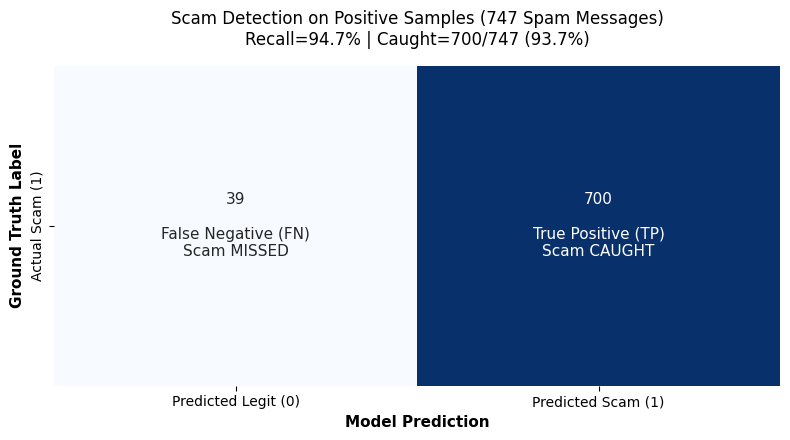

In [10]:
# Metrics Calculation & Confusion Matrix Plotting (Version-Aware)
try:
    import matplotlib.pyplot as plt
    import seaborn as sns
    HAS_PLOT_LIBS = True
except ImportError:
    HAS_PLOT_LIBS = False

# Locate cache file based on PROMPT_VERSION
version_str = globals().get('PROMPT_VERSION', 'v2')
candidates = [
    project_root / 'data' / f'benchmark_eval_cache_{version_str}.json',
    project_root / 'data' / 'benchmark_eval_cache.json',
    project_root / 'data' / 'benchmark_eval_cache_v1.json',
]
cache_path = next((p for p in candidates if p.is_file()), candidates[0])

if 'all_eval_results' in globals() and all_eval_results:
    records_list = all_eval_results['results'] if isinstance(all_eval_results, dict) else all_eval_results
else:
    with open(cache_path, 'r', encoding='utf-8') as f:
        data = json.load(f)
    records_list = data['results'] if isinstance(data, dict) and 'results' in data else (data if isinstance(data, list) else [])

eval_df = [r for r in records_list if r.get('ground_truth') is not None]

# Compute Counts
tp = sum(1 for r in eval_df if r['pred_label'] == 1 and r['ground_truth'] == 1)
fp = sum(1 for r in eval_df if r['pred_label'] == 1 and r['ground_truth'] == 0)
tn = sum(1 for r in eval_df if r['pred_label'] == 0 and r['ground_truth'] == 0)
fn = sum(1 for r in eval_df if r['pred_label'] == 0 and r['ground_truth'] == 1)
uncertain = sum(1 for r in eval_df if r['pred_label'] is None)
total = len(eval_df)
decided = total - uncertain

is_positive_only = all(r.get('ground_truth') == 1 for r in eval_df)

# Compute Key Metrics
raw_accuracy = (tp + tn) / total * 100 if total > 0 else 0.0
decided_accuracy = (tp + tn) / decided * 100 if decided > 0 else 0.0
recall = (tp / (tp + fn)) * 100 if (tp + fn) > 0 else 0.0
precision = (tp / (tp + fp)) * 100 if (tp + fp) > 0 else (100.0 if is_positive_only and tp > 0 else 0.0)
catch_rate_overall = (tp / total) * 100 if total > 0 else 0.0

print('=' * 65)
if is_positive_only:
    print(f'EVALUATION RESULTS ({cache_path.name}) - {total} SPAM MESSAGES')
    print('=' * 65)
    print(f'Total Real Scams Tested:     {total}')
    print(f'Scams Correctly CAUGHT (TP): {tp} ({catch_rate_overall:.2f}% of all spam)')
    print(f'Scams MISSED (FN):           {fn} ({(fn/total)*100:.2f}%)')
    print(f'Uncertain / Abstained:       {uncertain} ({(uncertain/total)*100:.2f}%)')
    print(f'Decided Scam Recall:         {recall:.2f}%  <-- [TP / (TP + FN) on decided calls]')
    print(f'Overall Catch Rate:          {catch_rate_overall:.2f}%  <-- [TP / Total tested]')
else:
    print(f'BENCHMARK EVALUATION RESULTS ({cache_path.name}) - {total} MESSAGES')
    print('=' * 65)
    print(f'Decided Accuracy:            {decided_accuracy:.2f}%  <-- [Accuracy on {decided} decided items]')
    print(f'Raw Accuracy:                {raw_accuracy:.2f}%  <-- [Penalizing {uncertain} abstentions as 0]')
    print(f'Scam Recall (Sensitivity):   {recall:.2f}%  <-- [Crucial: caught {tp}/{tp+fn} scams]')
    print(f'Scam Precision:              {precision:.2f}%  <-- [Quality: {tp}/{tp+fp} flags true]')
    print(f'Uncertain / Abstained:       {uncertain} ({(uncertain/total)*100:.1f}%)')
print('=' * 65)

# Check for v1 baseline comparison
v1_path = project_root / 'data' / 'benchmark_eval_cache_v1.json'
if v1_path.is_file() and cache_path.name != 'benchmark_eval_cache_v1.json':
    try:
        with open(v1_path, 'r', encoding='utf-8') as f:
            v1_data = json.load(f)
        v1_results = v1_data.get('results', [])
        v1_tp = sum(1 for r in v1_results if r.get('pred_label') == 1 and r.get('ground_truth') == 1)
        v1_total = len(v1_results)
        v1_rate = (v1_tp / v1_total) * 100 if v1_total > 0 else 0.0
        print(f'\n[VERSION COMPARISON]')
        print(f'  v1 Baseline:  {v1_tp}/{v1_total} caught ({v1_rate:.2f}%)')
        print(f'  Current ({version_str}): {tp}/{total} caught ({catch_rate_overall:.2f}%)')
        delta = catch_rate_overall - v1_rate
        prefix = '+' if delta >= 0 else ''
        print(f'  Improvement:  {prefix}{delta:.2f}% detection gain!')
    except Exception:
        pass

# Visual Plot
if HAS_PLOT_LIBS:
    fig, ax = plt.subplots(figsize=(8, 4.5 if is_positive_only else 6))
    if is_positive_only:
        cm = [[fn, tp]]
        labels = [['False Negative (FN)\nScam MISSED', 'True Positive (TP)\nScam CAUGHT']]
        sns.heatmap(
            cm,
            annot=[[f'{count}\n\n{label}' for count, label in zip(row_c, row_l)] for row_c, row_l in zip(cm, labels)],
            fmt='',
            cmap='Blues',
            cbar=False,
            xticklabels=['Predicted Legit (0)', 'Predicted Scam (1)'],
            yticklabels=['Actual Scam (1)'],
            annot_kws={'fontsize': 11}
        )
        plt.title(f'Scam Detection on Positive Samples ({total} Spam Messages)\nRecall={recall:.1f}% | Caught={tp}/{total} ({catch_rate_overall:.1f}%)', fontsize=12, pad=15)
    else:
        cm = [[tn, fp], [fn, tp]]
        labels = [
            ['True Negative (TN)\nBenign correctly passed', 'False Positive (FP)\nBenign falsely blocked'],
            ['False Negative (FN)\nScam MISSED', 'True Positive (TP)\nScam CAUGHT'],
        ]
        sns.heatmap(
            cm,
            annot=[[f'{count}\n\n{label}' for count, label in zip(row_c, row_l)] for row_c, row_l in zip(cm, labels)],
            fmt='',
            cmap='Blues',
            cbar=False,
            xticklabels=['Predicted Legit (0)', 'Predicted Scam (1)'],
            yticklabels=['Actual Legit (0)', 'Actual Scam (1)'],
            annot_kws={'fontsize': 11}
        )
        plt.title(f'ScamLens-AI Confusion Matrix\nRecall={recall:.1f}% | Decided Acc={decided_accuracy:.1f}%', fontsize=12, pad=15)
    
    plt.ylabel('Ground Truth Label', fontsize=11, fontweight='bold')
    plt.xlabel('Model Prediction', fontsize=11, fontweight='bold')
    plt.tight_layout()
    plt.show()
